In [ ]:
from google.colab import files

uploaded = files.upload()

Saving 01_HighQuality_Enhanced.jpg to 01_HighQuality_Enhanced (1).jpg
Saving 02_LowContrast.jpg to 02_LowContrast (1).jpg
Saving 03_Blurred.jpg to 03_Blurred (1).jpg
Saving 04_HighNoise.jpg to 04_HighNoise (1).jpg
Saving 05_LowResolution_Upsampled.jpg to 05_LowResolution_Upsampled (1).jpg
Saving 06_Faded_Underexposed.jpg to 06_Faded_Underexposed (1).jpg
Saving 07_ColorShift_WarmTint.jpg to 07_ColorShift_WarmTint (1).jpg
Saving 08_JPEGCompression_Artifacts.jpg to 08_JPEGCompression_Artifacts (1).jpg
Saving 09_CombinedDegradation.jpg to 09_CombinedDegradation (1).jpg


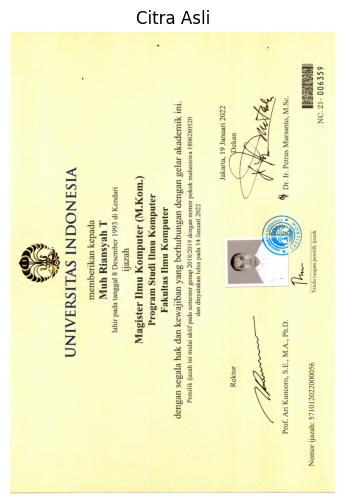

In [ ]:
import cv2
import matplotlib.pyplot as plt

nama_file = list(uploaded.keys())[0]

citra = cv2.imread(nama_file)
citra_rgb = cv2.cvtColor(citra, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 6))
plt.imshow(citra_rgb)
plt.axis("off")
plt.title("Citra Asli")
plt.show()

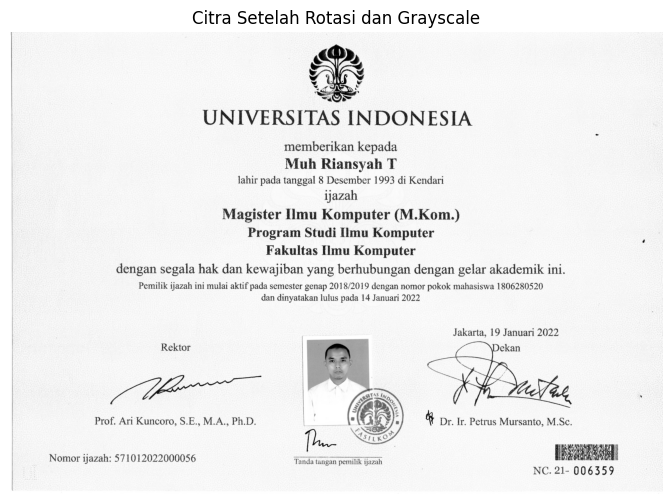

In [ ]:
citra_rotasi = cv2.rotate(citra, cv2.ROTATE_90_CLOCKWISE)

citra_gray = cv2.cvtColor(citra_rotasi, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(10, 6))
plt.imshow(citra_gray, cmap="gray")
plt.axis("off")
plt.title("Citra Setelah Rotasi dan Grayscale")
plt.show()

In [ ]:
kernel_mean = (5, 5)

citra_mean = cv2.blur(citra_gray, kernel_mean)

In [ ]:
kernel_median = 5

citra_median = cv2.medianBlur(citra_gray, kernel_median)

In [ ]:
citra_gaussian = cv2.GaussianBlur(
    citra_gray,
    (5, 5),
    0
)

In [ ]:
import numpy as np

kernel_sharpening = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

citra_sharpening = cv2.filter2D(
    citra_gray,
    -1,
    kernel_sharpening
)

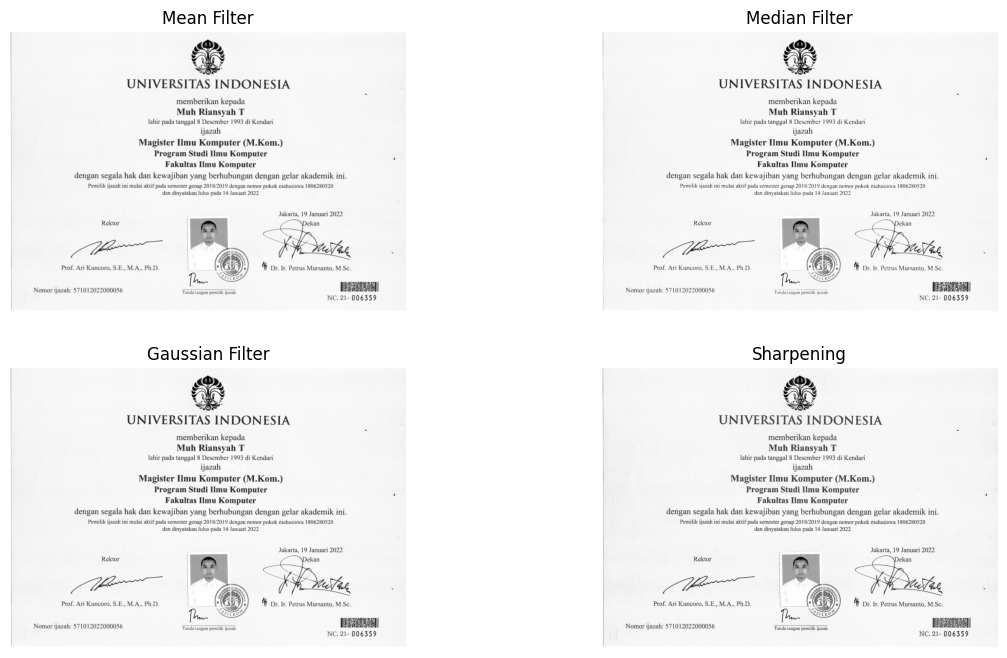

In [ ]:
plt.figure(figsize=(14, 8))

plt.subplot(2, 2, 1)
plt.imshow(citra_mean, cmap="gray")
plt.axis("off")
plt.title("Mean Filter")

plt.subplot(2, 2, 2)
plt.imshow(citra_median, cmap="gray")
plt.axis("off")
plt.title("Median Filter")

plt.subplot(2, 2, 3)
plt.imshow(citra_gaussian, cmap="gray")
plt.axis("off")
plt.title("Gaussian Filter")

plt.subplot(2, 2, 4)
plt.imshow(citra_sharpening, cmap="gray")
plt.axis("off")
plt.title("Sharpening")

plt.show()

In [ ]:
!apt-get update -qq
!apt-get install -y -qq tesseract-ocr
!pip install -q pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [ ]:
import pytesseract

konfigurasi_ocr = "--psm 7 -c tessedit_char_whitelist=0123456789"

In [ ]:
ocr_original = pytesseract.image_to_string(
    citra_gray,
    config=konfigurasi_ocr
).strip()

ocr_mean = pytesseract.image_to_string(
    citra_mean,
    config=konfigurasi_ocr
).strip()

ocr_median = pytesseract.image_to_string(
    citra_median,
    config=konfigurasi_ocr
).strip()

ocr_gaussian = pytesseract.image_to_string(
    citra_gaussian,
    config=konfigurasi_ocr
).strip()

ocr_sharpening = pytesseract.image_to_string(
    citra_sharpening,
    config=konfigurasi_ocr
).strip()

In [ ]:
hasil_ocr = {
    "Original": ocr_original,
    "Mean Filter": ocr_mean,
    "Median Filter": ocr_median,
    "Gaussian Filter": ocr_gaussian,
    "Sharpening": ocr_sharpening
}